# Proyecto Integrador — Fase 2: datos, modelamiento y validación
**Machine Learning I · Ciencia de Datos · Universidad Externado de Colombia**

**Problema predictivo:** clasificar si un recién nacido tendrá **bajo peso al nacer (BPN, < 2 500 g)**
a partir de variables maternas medibles durante la gestación.
**Artículo base:** Feyisa et al. (2023), *Front. Public Health* 11:1213291 (estudio de casos y controles, Etiopía).

Este cuaderno corre de principio a fin (`Kernel > Restart & Run All`) y toda la aleatoriedad usa la semilla `SEED = 42`.

**Estructura (coincide con las secciones del informe):**
1. Consolidación de los datos · 2. Flujo reproducible sin fuga · 3. Entrenamiento y comparación · 4. Validación, métricas e interpretación

In [1]:
import warnings, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed

from sklearn.base import BaseEstimator, TransformerMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     GridSearchCV, cross_val_predict)
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.linear_model import LogisticRegression, RidgeClassifier
from sklearn.metrics import (average_precision_score, roc_auc_score, brier_score_loss, precision_recall_curve,
                             roc_curve, confusion_matrix, fbeta_score, recall_score, precision_score)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance
from imblearn.pipeline import Pipeline            # compatible con pasos de sklearn y permite SMOTE
from imblearn.over_sampling import SMOTE

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
DATA = Path("data"); RES = Path("resultados"); RES.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 9})

## 1. Consolidación de los datos

**Decisión de diseño.** El artículo es de *casos y controles* (81 casos y 243 controles → 25 % de BPN por construcción del muestreo)
y tiene solo 324 registros de Etiopía. Entrenar con esa proporción inflaría la precisión de cualquier modelo. Por eso se **simula una cohorte**
colombiana de 6 000 gestantes (`01_simulacion.py`, semilla 42) con tres tipos de parámetros:
- **Del artículo:** proporción de cada exposición (controles, su Tabla 2) y efectos (odds ratios ajustados, su Tabla 3):
  sin consejería nutricional 2.4, MUAC < 23 cm 3.1, estrés alto 2.8, < 4 controles prenatales 2.8.
- **De fuentes colombianas:** prevalencia de BPN 9.7 % (DANE 2021; 9.1 % a 10.4 % en 2018-2022), edad, nivel educativo y controles prenatales
  de la madre (DANE, Estadísticas Vitales 2021), zona rural 22.9 % (Censo 2018) y régimen subsidiado 52.5 % (Boletín 17 del Externado, oct.-dic. 2025).
- **Supuestos del equipo:** medias y desviaciones de las variables continuas sin cifra publicada (MUAC, hemoglobina, ganancia de peso),
  correlaciones entre exposiciones, efectos leves (OR 1.2 a 1.5) de las variables no significativas, y los faltantes y errores de digitación.

Variables sin efecto directo (educación, zona, régimen, embarazo planeado, comidas extra, otros problemas) actúan como ruido que los modelos deben ignorar.
El estrés (PSS, 0 a 40) se genera con una distribución Beta escalada, acotada y asimétrica, calibrada a las categorías del artículo.

In [2]:
df = pd.read_csv(DATA / "gestantes_simulado.csv")
y = df.pop("bpn").astype(int)
X = df
print(f"Registros: {len(X)} | Variables: {X.shape[1]} | BPN: {y.sum()} ({y.mean():.1%})")
X.head()

Registros: 6000 | Variables: 15 | BPN: 572 (9.5%)


,edad,nivel_educativo,zona_rural,regimen_subsidiado,embarazo_planeado,consejeria_nutricional,comidas_adicionales,hta_embarazo,otro_problema_salud,muac_cm,puntaje_pss,n_controles_prenatales,n_tabletas_hierro,hemoglobina_gdl,ganancia_peso_kg
0,25.0,secundaria,si,no,no,si,si,no,no,23.6,19.0,4.0,83.0,10.6,15.7
1,27.0,superior,no,no,si,si,no,no,no,25.5,11.0,10.0,200.0,12.3,11.3
2,24.0,primaria,no,no,no,si,no,no,si,21.0,27.0,2.0,103.0,12.3,NaN
3,25.0,primaria,no,si,no,no,si,si,no,20.5,25.0,1.0,1.0,11.3,15.1
4,25.0,NaN,no,no,si,si,si,no,no,26.4,0.0,7.0,85.0,12.5,15.5


In [3]:
# Verificación de la simulación frente a sus fuentes (artículo y fuentes colombianas)
ver = pd.read_csv(DATA / "verificacion_proporciones.csv")
ver["diferencia"] = (ver["simulado"] - ver["referencia"]).round(3)
print("Máxima diferencia absoluta:", ver["diferencia"].abs().max())
ver

Máxima diferencia absoluta: 0.023


,variable,simulado,referencia,fuente,diferencia
0,sin consejería nutricional,0.399,0.399,Artículo (controles),0.000
1,MUAC < 23 cm,0.249,0.263,Artículo (controles),-0.014
2,estrés alto (PSS >= 27),0.151,0.148,Artículo (controles),0.003
3,estrés moderado (14-26),0.396,0.399,Artículo (controles),-0.003
4,< 4 controles prenatales,0.184,0.184,DANE EEVV 2021,0.000
5,anemia (Hb < 11),0.062,0.070,Artículo (controles),-0.008
6,hierro < 100 tabletas,0.478,0.455,Artículo (controles),0.023
7,HTA del embarazo,0.058,0.058,Artículo (controles),0.000
8,ganancia de peso < 12 kg,0.390,0.395,Artículo (controles),-0.005
9,comidas adicionales,0.564,0.564,Artículo (controles),0.000


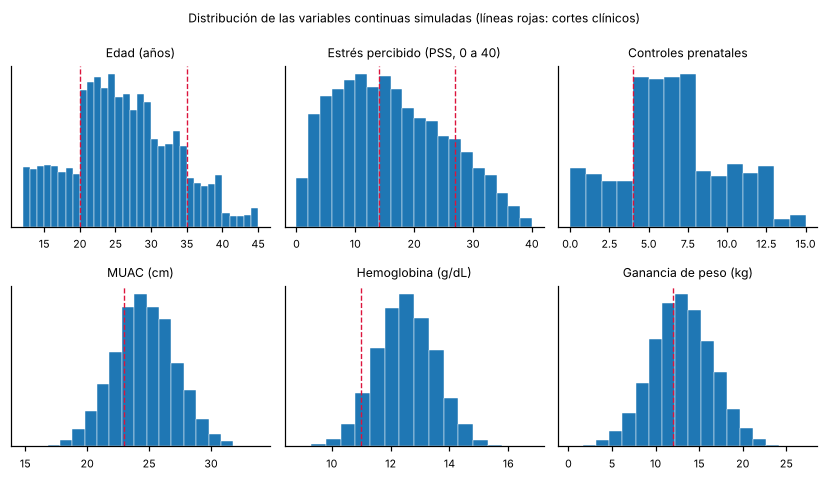

       edad  puntaje_pss  n_controles_prenatales  muac_cm  hemoglobina_gdl  \
mean  25.60        15.66                    6.06     24.6            12.48   
std    7.17         9.22                    3.28      2.5             1.00   
min   12.00         0.00                    0.00     14.8             8.80   
max   45.00        40.00                   15.00     32.9            16.40   

      ganancia_peso_kg  
mean              13.0  
std                3.5  
min                0.2  
max               26.6  
PSS en 0: 0.6 % | en 40: 0.0 %


In [4]:
# Distribuciones de las variables continuas (datos limpios, antes de inyectar faltantes y errores)
limpio = pd.read_csv(DATA / "gestantes_simulado_limpio.csv")
fig, ax = plt.subplots(2, 3, figsize=(7.6, 4.4))
specs = [("edad", "Edad (años)", 1), ("puntaje_pss", "Estrés percibido (PSS, 0 a 40)", 2), ("n_controles_prenatales", "Controles prenatales", 1),
         ("muac_cm", "MUAC (cm)", 1.0), ("hemoglobina_gdl", "Hemoglobina (g/dL)", 0.5), ("ganancia_peso_kg", "Ganancia de peso (kg)", 1.5)]
cortes = {"puntaje_pss": [14, 27], "n_controles_prenatales": [4], "muac_cm": [23], "hemoglobina_gdl": [11], "ganancia_peso_kg": [12], "edad": [20, 35]}
for a, (c, titulo, w) in zip(ax.ravel(), specs):
    v = limpio[c]
    a.hist(v, bins=np.arange(v.min(), v.max() + w, w), color="C0", edgecolor="white", linewidth=0.3)
    for k in cortes[c]:
        a.axvline(k, color="crimson", ls="--", lw=0.9)
    a.set_title(titulo, fontsize=8); a.tick_params(labelsize=7); a.set_yticks([])
fig.suptitle("Distribución de las variables continuas simuladas (líneas rojas: cortes clínicos)", fontsize=8)
fig.tight_layout(); fig.savefig(RES / "fig_distribuciones.png", dpi=200); plt.show()
print(limpio[[s[0] for s in specs]].describe().loc[["mean", "std", "min", "max"]].round(2))
print("PSS en 0:", round((limpio.puntaje_pss == 0).mean() * 100, 1), "% | en 40:", round((limpio.puntaje_pss == 40).mean() * 100, 1), "%")

In [5]:
# Calidad de los datos: faltantes y valores fuera de rango clínico
RANGOS = {"edad": (12, 50), "muac_cm": (14, 40), "puntaje_pss": (0, 40), "n_controles_prenatales": (0, 20),
          "n_tabletas_hierro": (0, 400), "hemoglobina_gdl": (5, 18), "ganancia_peso_kg": (-5, 35)}
calidad = pd.DataFrame({
    "faltantes_%": (X.isna().mean() * 100).round(1),
    "fuera_de_rango": pd.Series({c: int(((X[c] < lo) | (X[c] > hi)).sum()) for c, (lo, hi) in RANGOS.items()}),
}).fillna({"fuera_de_rango": 0}).astype({"fuera_de_rango": int})
calidad = calidad[(calidad["faltantes_%"] > 0) | (calidad["fuera_de_rango"] > 0)]
calidad

,faltantes_%,fuera_de_rango
comidas_adicionales,2.0,0
consejeria_nutricional,3.1,0
ganancia_peso_kg,8.2,0
hemoglobina_gdl,8.0,3
muac_cm,2.9,6
n_controles_prenatales,0.0,3
n_tabletas_hierro,7.1,0
nivel_educativo,2.0,0
puntaje_pss,5.2,0


**Transformaciones necesarias** (se implementan *dentro* del flujo, sección 2): valores fuera de rango → faltante; imputación (mediana / moda);
codificación one-hot; escalamiento de la edad; dicotomización con **puntos de corte clínicos fijos** del paper (MUAC < 23 cm, PSS ≥ 27, < 4 controles, Hb < 11 g/dL, etc.).

### Partición de prueba (se toca una sola vez, al final)

In [6]:
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.20, stratify=y, random_state=SEED)
print(f"Entrenamiento: {len(X_tr)} (BPN {y_tr.mean():.1%}) | Prueba: {len(X_te)} (BPN {y_te.mean():.1%})")

Entrenamiento: 4800 (BPN 9.5%) | Prueba: 1200 (BPN 9.5%)


## 2. Flujo reproducible sin fuga de datos

Todo el preprocesamiento vive dentro de un `Pipeline`. Orden de las etapas:

| # | Etapa | ¿Aprende de los datos? | Por qué no hay fuga |
|---|-------|------------------------|---------------------|
| 1 | `LimpiarRangos`: fuera de rango clínico → NaN | No (reglas fijas) | No usa estadísticos de la muestra |
| 2 | `BanderasClinicas`: puntos de corte del paper | No (cortes fijados *a priori* por la literatura) | Los umbrales no se eligen mirando el desenlace |
| 3 | Imputación (mediana / moda) | **Sí** | Se ajusta solo con el entrenamiento de cada partición |
| 4 | Escalamiento (edad) y one-hot | **Sí** | Ídem |
| 5 | SMOTE (solo en la variante que lo usa) | **Sí** | Se aplica solo al entrenamiento; el pliegue de validación nunca se sobremuestrea |
| 6 | Modelo | **Sí** | Hiperparámetros elegidos con CV interna, nunca con el pliegue externo |

La búsqueda de hiperparámetros está **anidada** dentro de la validación externa, y el umbral de decisión se elige con predicciones fuera de muestra del propio entrenamiento.

In [7]:
class LimpiarRangos(BaseEstimator, TransformerMixin):
    """Sin estado: valores fuera de rango clínico -> NaN (se imputan después, con estadísticos del entrenamiento)."""
    def __init__(self, rangos=None):
        self.rangos = rangos
    def fit(self, X, y=None):
        return self
    def transform(self, X):
        X = X.copy()
        for c, (lo, hi) in (self.rangos or RANGOS).items():
            if c in X:
                X[c] = X[c].where((X[c] >= lo) & (X[c] <= hi))
        return X


RAW_UMBRAL = ["muac_cm", "puntaje_pss", "n_controles_prenatales", "n_tabletas_hierro", "hemoglobina_gdl", "ganancia_peso_kg"]
BANDERAS = ["edad_extrema", "muac_lt23", "anc_lt4", "anemia", "hierro_lt100", "gwg_lt12"]


class BanderasClinicas(BaseEstimator, TransformerMixin):
    """Sin estado: dicotomiza con cortes clínicos fijos, preservando los NaN. Si usar=False deja las variables crudas."""
    def __init__(self, usar=True):
        self.usar = usar
    def fit(self, X, y=None):
        return self
    @staticmethod
    def _f(col, cond):
        f = cond.astype(float)
        f[col.isna()] = np.nan
        return f
    def transform(self, X):
        X = X.copy()
        if not self.usar:
            return X
        X["edad_extrema"] = self._f(X["edad"], (X["edad"] < 20) | (X["edad"] >= 35))
        X["muac_lt23"] = self._f(X["muac_cm"], X["muac_cm"] < 23)
        X["anc_lt4"] = self._f(X["n_controles_prenatales"], X["n_controles_prenatales"] < 4)
        X["anemia"] = self._f(X["hemoglobina_gdl"], X["hemoglobina_gdl"] < 11)
        X["hierro_lt100"] = self._f(X["n_tabletas_hierro"], X["n_tabletas_hierro"] < 100)
        X["gwg_lt12"] = self._f(X["ganancia_peso_kg"], X["ganancia_peso_kg"] < 12)
        X["estres_cat"] = pd.Series(np.select([X["puntaje_pss"] >= 27, X["puntaje_pss"] >= 14], ["alto", "moderado"], "bajo"),
                                    index=X.index).mask(X["puntaje_pss"].isna())
        return X.drop(columns=RAW_UMBRAL)


CAT_SPEC = {  # primera categoría = referencia (misma lógica del paper: la categoría de menor riesgo)
    "nivel_educativo": ["superior", "secundaria", "primaria", "ninguna"],
    "zona_rural": ["no", "si"], "regimen_subsidiado": ["no", "si"], "embarazo_planeado": ["no", "si"],
    "consejeria_nutricional": ["si", "no"], "comidas_adicionales": ["no", "si"], "hta_embarazo": ["no", "si"],
    "otro_problema_salud": ["no", "si"],
}
NUM_CRUDAS = ["edad"] + RAW_UMBRAL


def crear_prep(usar_banderas=True):
    cat_spec = dict(CAT_SPEC)
    if usar_banderas:
        cat_spec["estres_cat"] = ["bajo", "moderado", "alto"]
    num = ["edad"] if usar_banderas else NUM_CRUDAS
    transformers = [
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("ohe", OneHotEncoder(categories=list(cat_spec.values()), drop="first",
                                                handle_unknown="ignore", sparse_output=False))]), list(cat_spec)),
    ]
    if usar_banderas:
        transformers.append(("bin", SimpleImputer(strategy="most_frequent"), BANDERAS))
    return ColumnTransformer(transformers, verbose_feature_names_out=False)


def armar(modelo, usar_banderas=True, smote=False):
    pasos = [("limpiar", LimpiarRangos()), ("banderas", BanderasClinicas(usar=usar_banderas)),
             ("prep", crear_prep(usar_banderas))]
    if smote:
        pasos.append(("smote", SMOTE(random_state=SEED)))
    pasos.append(("modelo", modelo))
    return Pipeline(pasos)


# Verificación rápida: el flujo entrega una matriz sin faltantes y con nombres de variable interpretables
_p = armar(LogisticRegression(max_iter=2000)).fit(X_tr, y_tr)
_M = _p[:-1].transform(X_tr)
print("Matriz de diseño:", _M.shape, "| NaN:", int(np.isnan(_M).sum()))
print(list(_p["prep"].get_feature_names_out()))

Matriz de diseño: (4800, 19) | NaN: 0
['edad', 'nivel_educativo_secundaria', 'nivel_educativo_primaria', 'nivel_educativo_ninguna', 'zona_rural_si', 'regimen_subsidiado_si', 'embarazo_planeado_si', 'consejeria_nutricional_no', 'comidas_adicionales_si', 'hta_embarazo_si', 'otro_problema_salud_si', 'estres_cat_moderado', 'estres_cat_alto', 'edad_extrema', 'muac_lt23', 'anc_lt4', 'anemia', 'hierro_lt100', 'gwg_lt12']


## 3. Entrenamiento y comparación de modelos

**Modelos del curso**: KNN, Naive Bayes, regresión lineal (Ridge), regresión logística (sin penalización, L2, L1, Elastic Net), LDA y QDA,
más tres variantes de la logística para tratar el desbalance (`class_weight`, SMOTE) y para medir el valor de las banderas clínicas.
**Línea base**: clasificador que siempre predice la prevalencia (`DummyClassifier(strategy="prior")`).

**Validación:** `RepeatedStratifiedKFold` 5×3 = 15 pliegues sobre el entrenamiento (estratificado por el desenlace, ~44 casos de BPN por pliegue);
hiperparámetros por `GridSearchCV` interna de 3 pliegues optimizando PR-AUC.

**Métricas** (BPN es ~9 %, la exactitud es engañosa: predecir "nadie" da 91 %):
- **PR-AUC** (principal, sensible a la prevalencia) y **ROC-AUC**.
- **Recall@20 %**: fracción de los BPN que caen entre el 20 % de gestantes con mayor riesgo (capacidad de tamizaje).
- **Recall, precisión y F2** con un umbral elegido por F2 con predicciones fuera de muestra del entrenamiento (F2 pondera más el recall: omitir un BPN cuesta más que una alarma falsa).
- **Brier** (calibración de probabilidades), cuando el modelo entrega probabilidades.

In [8]:
ESPECS = {
    "Línea base (prior)": (armar(DummyClassifier(strategy="prior")), {}),
    "KNN": (armar(KNeighborsClassifier()), {"modelo__n_neighbors": [15, 31, 61, 101], "modelo__weights": ["uniform", "distance"]}),
    "Naive Bayes": (armar(GaussianNB()), {"modelo__var_smoothing": [1e-9, 1e-6, 1e-3, 1e-1]}),
    "LDA": (armar(LinearDiscriminantAnalysis(solver="lsqr")), {"modelo__shrinkage": [None, "auto"]}),
    "QDA": (armar(QuadraticDiscriminantAnalysis()), {"modelo__reg_param": [0.1, 0.3, 0.6, 0.9]}),
    "Regresión lineal (Ridge)": (armar(RidgeClassifier()), {"modelo__alpha": [0.1, 1, 10, 100, 1000]}),
    "Logística sin penalización": (armar(LogisticRegression(C=np.inf, max_iter=3000)), {}),
    "Logística L2 (Ridge)": (armar(LogisticRegression(l1_ratio=0.0, max_iter=3000)), {"modelo__C": [0.01, 0.1, 1, 10]}),
    "Logística L1 (Lasso)": (armar(LogisticRegression(l1_ratio=1.0, solver="liblinear")), {"modelo__C": [0.01, 0.03, 0.1, 0.3, 1]}),
    "Logística Elastic Net": (armar(LogisticRegression(solver="saga", max_iter=5000)),
                              {"modelo__C": [0.03, 0.1, 0.3, 1], "modelo__l1_ratio": [0.2, 0.5, 0.8]}),
    "Logística L2 + class_weight": (armar(LogisticRegression(l1_ratio=0.0, class_weight="balanced", max_iter=3000)),
                                    {"modelo__C": [0.01, 0.1, 1, 10]}),
    "Logística L2 + SMOTE": (armar(LogisticRegression(l1_ratio=0.0, max_iter=3000), smote=True), {"modelo__C": [0.01, 0.1, 1, 10]}),
    "Logística L2 sin banderas": (armar(LogisticRegression(l1_ratio=0.0, max_iter=3000), usar_banderas=False),
                                  {"modelo__C": [0.01, 0.1, 1, 10]}),
}


def puntaje(est, Xm):
    return est.predict_proba(Xm)[:, 1] if hasattr(est, "predict_proba") else est.decision_function(Xm)


def umbral_f2(yv, s):
    p, r, t = precision_recall_curve(yv, s)
    f2 = 5 * p[:-1] * r[:-1] / np.maximum(4 * p[:-1] + r[:-1], 1e-12)
    return t[int(np.argmax(f2))]


def recall_top(yv, s, frac=0.20, seed=SEED):
    yv = np.asarray(yv)
    k = int(np.ceil(frac * len(yv)))
    orden = np.lexsort((np.random.default_rng(seed).random(len(s)), -s))[:k]   # desempates al azar
    return yv[orden].sum() / yv.sum()


def evaluar_fold(nombre, k, tr, te):
    base, grid = ESPECS[nombre]
    Xa, ya, Xb, yb = X_tr.iloc[tr], y_tr.iloc[tr], X_tr.iloc[te], y_tr.iloc[te]
    cv_in = StratifiedKFold(3, shuffle=True, random_state=SEED)
    if grid:
        gs = GridSearchCV(clone(base), grid, scoring="average_precision", cv=cv_in).fit(Xa, ya)
        est, params = gs.best_estimator_, gs.best_params_
    else:
        est, params = clone(base).fit(Xa, ya), {}
    metodo = "predict_proba" if hasattr(est, "predict_proba") else "decision_function"
    oof = cross_val_predict(clone(est), Xa, ya, cv=cv_in, method=metodo)
    oof = oof[:, 1] if metodo == "predict_proba" else oof
    thr = umbral_f2(ya.values, oof)                       # umbral SIN mirar el pliegue externo
    s = puntaje(est, Xb)
    pred = (s >= thr).astype(int)
    return dict(modelo=nombre, pliegue=k,
                pr_auc=average_precision_score(yb, s), roc_auc=roc_auc_score(yb, s),
                recall_top20=recall_top(yb, s), recall=recall_score(yb, pred), precision=precision_score(yb, pred, zero_division=0),
                f2=fbeta_score(yb, pred, beta=2), brier=brier_score_loss(yb, s) if metodo == "predict_proba" else np.nan,
                params=json.dumps(params, default=str))


cv_ext = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
folds = list(cv_ext.split(X_tr, y_tr))
trabajos = [(n, k, tr, te) for n in ESPECS for k, (tr, te) in enumerate(folds)]
filas = Parallel(n_jobs=2)(delayed(evaluar_fold)(*t) for t in trabajos)
res = pd.DataFrame(filas)
res.to_csv(RES / "resultados_por_pliegue.csv", index=False)
print(f"{len(res)} evaluaciones ({len(ESPECS)} modelos × {len(folds)} pliegues)")

195 evaluaciones (13 modelos × 15 pliegues)


In [9]:
METR = ["pr_auc", "roc_auc", "recall_top20", "recall", "precision", "f2", "brier"]
resumen = res.groupby("modelo")[METR].agg(["mean", "std"])
orden = resumen[("pr_auc", "mean")].sort_values(ascending=False).index
tabla = pd.DataFrame({m: [f"{resumen.loc[n, (m, 'mean')]:.3f} ± {resumen.loc[n, (m, 'std')]:.3f}" for n in orden] for m in METR},
                     index=orden)
tabla.to_csv(RES / "tabla_comparacion_modelos.csv")
tabla

,pr_auc,roc_auc,recall_top20,recall,precision,f2,brier
modelo,,,,,,,
Logística L2 + class_weight,0.342 ± 0.038,0.781 ± 0.018,0.563 ± 0.040,0.681 ± 0.070,0.212 ± 0.023,0.468 ± 0.026,0.189 ± 0.007
Logística Elastic Net,0.341 ± 0.042,0.784 ± 0.018,0.568 ± 0.041,0.691 ± 0.056,0.220 ± 0.021,0.482 ± 0.028,0.076 ± 0.002
Regresión lineal (Ridge),0.339 ± 0.039,0.782 ± 0.017,0.564 ± 0.037,0.709 ± 0.054,0.203 ± 0.014,0.472 ± 0.025,nan ± nan
Logística L1 (Lasso),0.338 ± 0.042,0.783 ± 0.018,0.563 ± 0.043,0.681 ± 0.077,0.216 ± 0.023,0.472 ± 0.033,0.075 ± 0.002
Logística L2 (Ridge),0.337 ± 0.038,0.781 ± 0.016,0.564 ± 0.040,0.681 ± 0.051,0.214 ± 0.017,0.473 ± 0.026,0.078 ± 0.001
Logística L2 + SMOTE,0.336 ± 0.039,0.778 ± 0.018,0.549 ± 0.050,0.682 ± 0.061,0.214 ± 0.015,0.473 ± 0.026,0.185 ± 0.007
Logística sin penalización,0.335 ± 0.041,0.782 ± 0.019,0.558 ± 0.040,0.680 ± 0.080,0.209 ± 0.027,0.463 ± 0.024,0.075 ± 0.003
LDA,0.332 ± 0.042,0.782 ± 0.019,0.552 ± 0.045,0.695 ± 0.057,0.213 ± 0.019,0.476 ± 0.025,0.077 ± 0.005
QDA,0.327 ± 0.036,0.771 ± 0.015,0.551 ± 0.037,0.679 ± 0.071,0.197 ± 0.017,0.454 ± 0.025,0.080 ± 0.001


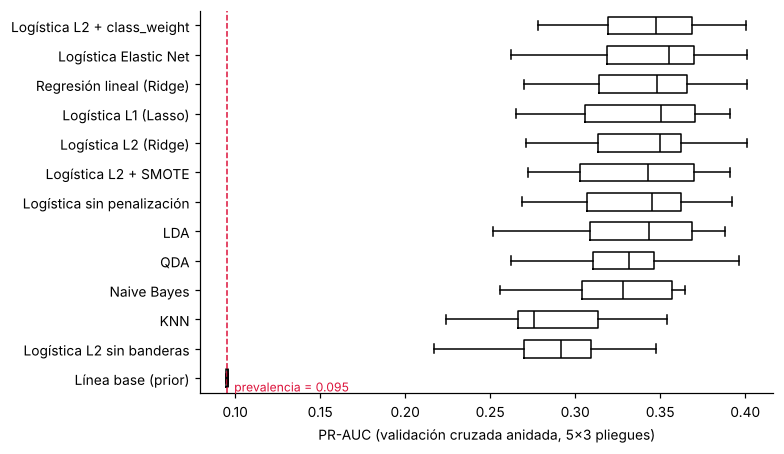

In [10]:
# Figura 2. Distribución de PR-AUC por modelo en los 15 pliegues externos
fig, ax = plt.subplots(figsize=(7.2, 4.2))
datos = [res.loc[res.modelo == n, "pr_auc"].values for n in orden[::-1]]
ax.boxplot(datos, vert=False, tick_labels=list(orden[::-1]), widths=0.6, medianprops=dict(color="k"))
ax.axvline(y_tr.mean(), color="crimson", ls="--", lw=1)
ax.text(y_tr.mean() + 0.004, 0.55, f"prevalencia = {y_tr.mean():.3f}", color="crimson", fontsize=8)
ax.set_xlabel("PR-AUC (validación cruzada anidada, 5×3 pliegues)")
fig.tight_layout(); fig.savefig(RES / "fig2_comparacion_modelos.png", dpi=200); plt.show()

In [11]:
# Estabilidad de hiperparámetros elegidos por la búsqueda interna
estab = (res[res.params != "{}"].groupby("modelo")["params"].agg(lambda s: s.value_counts().head(2).to_dict()))
estab

modelo
KNN                            {'{"modelo__n_neighbors": 101, "modelo__weight...
LDA                            {'{"modelo__shrinkage": "auto"}': 14, '{"model...
Logística Elastic Net          {'{"modelo__C": 0.03, "modelo__l1_ratio": 0.2}...
Logística L1 (Lasso)           {'{"modelo__C": 0.3}': 12, '{"modelo__C": 1}': 3}
Logística L2 (Ridge)           {'{"modelo__C": 0.01}': 12, '{"modelo__C": 0.1...
Logística L2 + SMOTE                                 {'{"modelo__C": 0.01}': 15}
Logística L2 + class_weight    {'{"modelo__C": 0.01}': 14, '{"modelo__C": 0.1...
Logística L2 sin banderas      {'{"modelo__C": 0.1}': 9, '{"modelo__C": 0.01}...
Naive Bayes                               {'{"modelo__var_smoothing": 0.1}': 15}
QDA                            {'{"modelo__reg_param": 0.9}': 8, '{"modelo__r...
Regresión lineal (Ridge)       {'{"modelo__alpha": 1000}': 14, '{"modelo__alp...
Name: params, dtype: object

In [12]:
# Diferencias pareadas (mismo pliegue) frente a la logística L2: ¿las diferencias superan la variabilidad?
ref = res[res.modelo == "Logística L2 (Ridge)"].set_index("pliegue")["pr_auc"]
dif = {n: (res[res.modelo == n].set_index("pliegue")["pr_auc"] - ref) for n in orden if n != "Logística L2 (Ridge)"}
pareado = pd.DataFrame({n: {"Δ PR-AUC medio": d.mean(), "sd": d.std(), "pliegues donde gana": int((d > 0).sum())} for n, d in dif.items()}).T
pareado.round(3)

,Δ PR-AUC medio,sd,pliegues donde gana
Logística L2 + class_weight,0.005,0.005,12.0
Logística Elastic Net,0.004,0.008,11.0
Regresión lineal (Ridge),0.002,0.004,11.0
Logística L1 (Lasso),0.001,0.010,9.0
Logística L2 + SMOTE,-0.001,0.009,8.0
Logística sin penalización,-0.002,0.008,6.0
LDA,-0.004,0.011,6.0
QDA,-0.010,0.014,1.0
Naive Bayes,-0.014,0.014,2.0
KNN,-0.050,0.030,0.0


### Elección del modelo final
Regla: entre los modelos cuya PR-AUC media está dentro de **una desviación estándar** de la mejor, se elige el más **simple e interpretable**
(parsimonia), porque el objetivo del proyecto es también explicar los factores de riesgo.

In [13]:
mejor = orden[0]
sd_mejor = resumen.loc[mejor, ("pr_auc", "std")]
candidatos = [n for n in orden if resumen.loc[n, ("pr_auc", "mean")] >= resumen.loc[mejor, ("pr_auc", "mean")] - sd_mejor]
print("Mejor por PR-AUC media:", mejor)
print("Dentro de 1 SD:", candidatos)

Mejor por PR-AUC media: Logística L2 + class_weight
Dentro de 1 SD: ['Logística L2 + class_weight', 'Logística Elastic Net', 'Regresión lineal (Ridge)', 'Logística L1 (Lasso)', 'Logística L2 (Ridge)', 'Logística L2 + SMOTE', 'Logística sin penalización', 'LDA', 'QDA', 'Naive Bayes']


In [14]:
MODELO_FINAL = "Logística L2 (Ridge)"   # ← ajustado tras revisar la tabla (ver justificación en el informe)
assert MODELO_FINAL in ESPECS

## 4. Validación final, métricas e interpretación
Ahora sí se usa la partición de prueba (20 %), que no participó en ninguna decisión.
El modelo final se reajusta con todo el entrenamiento (búsqueda interna de 5 pliegues) y el umbral se elige con predicciones fuera de muestra del entrenamiento.

In [15]:
base, grid = ESPECS[MODELO_FINAL]
cv5 = StratifiedKFold(5, shuffle=True, random_state=SEED)
gs = GridSearchCV(clone(base), grid, scoring="average_precision", cv=cv5).fit(X_tr, y_tr)
final = gs.best_estimator_
print("Hiperparámetros:", gs.best_params_)
oof = cross_val_predict(clone(final), X_tr, y_tr, cv=cv5, method="predict_proba")[:, 1]
THR = umbral_f2(y_tr.values, oof)
s_te = final.predict_proba(X_te)[:, 1]
pred_te = (s_te >= THR).astype(int)
print(f"Umbral de decisión (F2, fuera de muestra): {THR:.3f}")

def metricas(yv, s, pred):
    return dict(pr_auc=average_precision_score(yv, s), roc_auc=roc_auc_score(yv, s), recall_top20=recall_top(yv, s),
                recall=recall_score(yv, pred), precision=precision_score(yv, pred, zero_division=0),
                f2=fbeta_score(yv, pred, beta=2), brier=brier_score_loss(yv, s))

pt = metricas(y_te.values, s_te, pred_te)
rng = np.random.default_rng(SEED)
boot = []
for _ in range(1000):
    i = rng.integers(0, len(y_te), len(y_te))
    if y_te.values[i].sum() == 0:
        continue
    boot.append(metricas(y_te.values[i], s_te[i], pred_te[i]))
boot = pd.DataFrame(boot)
final_tab = pd.DataFrame({"estimación": pd.Series(pt), "IC95% inf": boot.quantile(0.025), "IC95% sup": boot.quantile(0.975)}).round(3)
final_tab.to_csv(RES / "metricas_prueba.csv")
final_tab

Hiperparámetros: {'modelo__C': 0.01}


Umbral de decisión (F2, fuera de muestra): 0.097


,estimación,IC95% inf,IC95% sup
pr_auc,0.320,0.245,0.413
roc_auc,0.746,0.690,0.797
recall_top20,0.553,0.464,0.636
recall,0.667,0.575,0.754
precision,0.184,0.145,0.225
f2,0.438,0.370,0.499
brier,0.078,0.066,0.091


In [16]:
tn, fp, fn, tp = confusion_matrix(y_te, pred_te).ravel()
print(f"Matriz de confusión (prueba, n={len(y_te)}): TP={tp}  FN={fn}  FP={fp}  TN={tn}")
print(f"Exactitud = {(tp+tn)/len(y_te):.3f}  (referencia ingenua 'nadie tiene BPN' = {1-y_te.mean():.3f})")

# Línea base en la prueba
base_pr = y_te.mean()
print(f"Línea base: PR-AUC = {base_pr:.3f}, ROC-AUC = 0.500, recall@20% ≈ 0.20")

Matriz de confusión (prueba, n=1200): TP=76  FN=38  FP=336  TN=750
Exactitud = 0.688  (referencia ingenua 'nadie tiene BPN' = 0.905)
Línea base: PR-AUC = 0.095, ROC-AUC = 0.500, recall@20% ≈ 0.20


In [17]:
# Techo de desempeño (solo posible en datos simulados): la probabilidad verdadera de BPN usada para generar los datos
p_ver = pd.read_csv(DATA / "prob_verdadera_simulacion.csv")["p_verdadera"]
p_te = p_ver.loc[X_te.index].values
techo = dict(pr_auc=average_precision_score(y_te, p_te), roc_auc=roc_auc_score(y_te, p_te), recall_top20=recall_top(y_te.values, p_te))
print("Techo con la probabilidad verdadera (prueba):", {k: round(v, 3) for k, v in techo.items()})

Techo con la probabilidad verdadera (prueba): {'pr_auc': 0.309, 'roc_auc': 0.751, 'recall_top20': np.float64(0.535)}


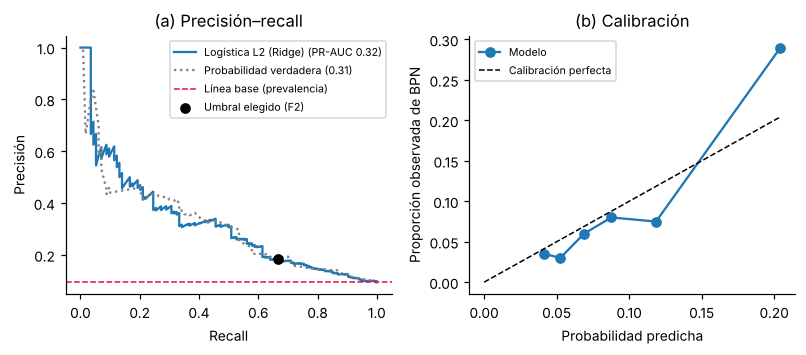

In [18]:
# Figura 3. Curva precisión-recall y calibración en la prueba
fig, ax = plt.subplots(1, 2, figsize=(7.4, 3.3))
p, r, _ = precision_recall_curve(y_te, s_te)
pv, rv, _ = precision_recall_curve(y_te, p_te)
ax[0].plot(r, p, label=f"{MODELO_FINAL} (PR-AUC {pt['pr_auc']:.2f})")
ax[0].plot(rv, pv, color="gray", ls=":", label=f"Probabilidad verdadera ({techo['pr_auc']:.2f})")
ax[0].axhline(y_te.mean(), color="crimson", ls="--", lw=1, label="Línea base (prevalencia)")
ax[0].scatter([pt["recall"]], [pt["precision"]], color="k", zorder=5, label="Umbral elegido (F2)")
ax[0].set_xlabel("Recall"); ax[0].set_ylabel("Precisión"); ax[0].legend(fontsize=7); ax[0].set_title("(a) Precisión–recall")
fr, mp = calibration_curve(y_te, s_te, n_bins=6, strategy="quantile")
ax[1].plot(mp, fr, "o-", label="Modelo"); ax[1].plot([0, mp.max()], [0, mp.max()], "k--", lw=1, label="Calibración perfecta")
ax[1].set_xlabel("Probabilidad predicha"); ax[1].set_ylabel("Proporción observada de BPN"); ax[1].legend(fontsize=7); ax[1].set_title("(b) Calibración")
fig.tight_layout(); fig.savefig(RES / "fig3_prueba.png", dpi=200); plt.show()

### Interpretación del mejor modelo
**(i) Odds ratios** (regresión logística sin penalización sobre el entrenamiento con el mismo preprocesamiento, para tener intervalos de confianza)
comparados con los odds ratios ajustados del paper. En una simulación sabemos además el efecto verdadero, lo que valida la simulación.

In [19]:
import statsmodels.api as sm
M = _p[:-1].transform(X_tr)
M = pd.DataFrame(M, columns=_p["prep"].get_feature_names_out(), index=X_tr.index)
glm = sm.Logit(y_tr, sm.add_constant(M)).fit(disp=0)
coef = glm.params.drop("const"); ic = glm.conf_int().drop("const")

mapa = [  # (etiqueta, columna, invertir signo, OR del paper, OR generador)
    ("Sin consejería nutricional", "consejeria_nutricional_no", False, 2.4, 2.4),
    ("MUAC < 23 cm", "muac_lt23", False, 3.1, 3.1),
    ("Estrés alto (PSS ≥ 27)", "estres_cat_alto", False, 2.8, 2.8),
    ("Estrés moderado", "estres_cat_moderado", False, 0.86, 1.0),
    ("< 4 controles prenatales", "anc_lt4", False, 2.8, 2.8),
    ("Anemia (Hb < 11)", "anemia", False, 2.4, 1.5),
    ("Hierro < 100 tabletas", "hierro_lt100", False, 1.4, 1.3),
    ("HTA del embarazo", "hta_embarazo_si", False, 1.04, 1.2),
    ("Ganancia de peso < 12 kg", "gwg_lt12", False, np.nan, 1.3),
    ("Edad < 20 o ≥ 35", "edad_extrema", False, np.nan, 1.3),
    ("Zona rural", "zona_rural_si", False, np.nan, 1.0),
    ("Régimen subsidiado", "regimen_subsidiado_si", False, np.nan, 1.0),
]
tab_or = pd.DataFrame([{"variable": l, "OR paper (AOR)": op, "OR generador": og,
                        "OR estimado": np.exp(coef[c]), "IC95% inf": np.exp(ic.loc[c, 0]), "IC95% sup": np.exp(ic.loc[c, 1]),
                        "p": glm.pvalues[c]} for l, c, _i, op, og in mapa])
tab_or["¿IC contiene OR generador?"] = (tab_or["IC95% inf"] <= tab_or["OR generador"]) & (tab_or["OR generador"] <= tab_or["IC95% sup"])
tab_or.round(2).to_csv(RES / "tabla_odds_ratios.csv", index=False)
tab_or.round(2)

,variable,OR paper (AOR),OR generador,OR estimado,IC95% inf,IC95% sup,p,¿IC contiene OR generador?
0,Sin consejería nutricional,2.40,2.4,2.48,1.98,3.10,0.00,True
1,MUAC < 23 cm,3.10,3.1,3.33,2.68,4.12,0.00,True
2,Estrés alto (PSS ≥ 27),2.80,2.8,2.55,1.97,3.32,0.00,True
3,Estrés moderado,0.86,1.0,0.81,0.63,1.03,0.09,True
4,< 4 controles prenatales,2.80,2.8,2.67,2.12,3.35,0.00,True
5,Anemia (Hb < 11),2.40,1.5,1.13,0.78,1.63,0.53,True
6,Hierro < 100 tabletas,1.40,1.3,1.43,1.16,1.76,0.00,True
7,HTA del embarazo,1.04,1.2,1.21,0.79,1.83,0.38,True
8,Ganancia de peso < 12 kg,NaN,1.3,1.33,1.07,1.64,0.01,True
9,Edad < 20 o ≥ 35,NaN,1.3,1.03,0.82,1.30,0.78,True


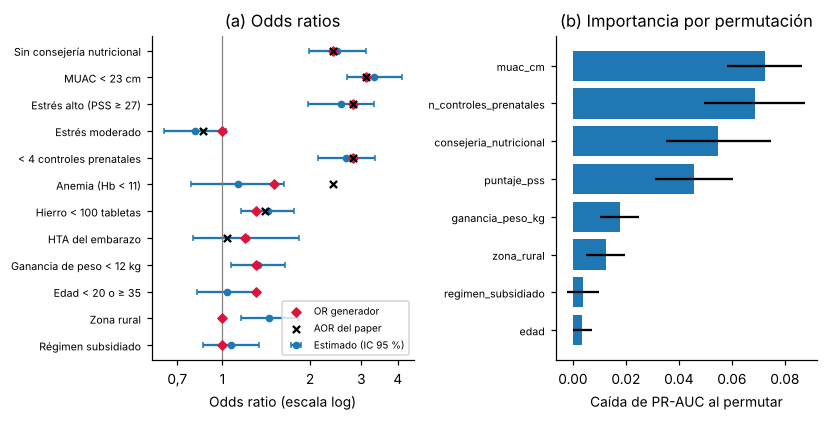

,variable,caida_pr_auc,sd
9,muac_cm,0.0724,0.0142
11,n_controles_prenatales,0.0686,0.0192
5,consejeria_nutricional,0.0549,0.0198
10,puntaje_pss,0.0458,0.0147
14,ganancia_peso_kg,0.0176,0.0075
2,zona_rural,0.0123,0.0075
3,regimen_subsidiado,0.0038,0.0059
0,edad,0.0036,0.0036


In [20]:
# (ii) Importancia por permutación (sobre las variables originales, en la prueba) y OR en un solo gráfico
pi = permutation_importance(final, X_te, y_te, scoring="average_precision", n_repeats=30, random_state=SEED, n_jobs=2)
imp = pd.DataFrame({"variable": X_te.columns, "caida_pr_auc": pi.importances_mean, "sd": pi.importances_std}).sort_values("caida_pr_auc", ascending=False)
imp.round(4).to_csv(RES / "importancia_permutacion.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(7.6, 3.9))
t = tab_or.iloc[::-1]
yy = np.arange(len(t))
ax[0].errorbar(t["OR estimado"], yy, xerr=[t["OR estimado"] - t["IC95% inf"], t["IC95% sup"] - t["OR estimado"]], fmt="o", color="C0", ms=4, capsize=2, label="Estimado (IC 95 %)")
ax[0].scatter(t["OR generador"], yy, marker="D", color="crimson", s=18, zorder=5, label="OR generador")
ax[0].scatter(t["OR paper (AOR)"], yy, marker="x", color="k", s=22, zorder=5, label="AOR del paper")
ax[0].axvline(1, color="gray", lw=0.8); ax[0].set_xscale("log"); ax[0].set_xticks([0.7, 1, 2, 3, 4]); ax[0].set_xticklabels(["0,7", "1", "2", "3", "4"]); ax[0].minorticks_off(); ax[0].set_yticks(yy); ax[0].set_yticklabels(t["variable"], fontsize=7)
ax[0].set_xlabel("Odds ratio (escala log)"); ax[0].legend(fontsize=6.5, loc="lower right"); ax[0].set_title("(a) Odds ratios")
top = imp.head(8).iloc[::-1]
ax[1].barh(top["variable"], top["caida_pr_auc"], xerr=top["sd"], color="C0")
ax[1].set_xlabel("Caída de PR-AUC al permutar"); ax[1].set_title("(b) Importancia por permutación"); ax[1].tick_params(axis="y", labelsize=7)
fig.tight_layout(); fig.savefig(RES / "fig4_interpretacion.png", dpi=200); plt.show()
imp.head(8).round(4)

**(iii) Análisis de errores:** ¿qué gestantes se le escapan al modelo?

In [21]:
fl = BanderasClinicas().transform(LimpiarRangos().transform(X_te))
clave = (fl["muac_lt23"].fillna(0) + fl["anc_lt4"].fillna(0) + (fl["estres_cat"] == "alto").astype(float)
         + (X_te["consejeria_nutricional"] == "no").astype(float))
grupo = np.where((y_te == 1) & (pred_te == 1), "VP (BPN detectado)", np.where((y_te == 1), "FN (BPN omitido)",
                 np.where(pred_te == 1, "FP (falsa alarma)", "VN")))
err = pd.DataFrame({"grupo": grupo, "n_factores_clave": clave.values})
tab_err = err.groupby("grupo")["n_factores_clave"].agg(n="size", factores_clave_promedio="mean", sin_ningun_factor=lambda s: (s == 0).mean()).round(2)
tab_err.to_csv(RES / "analisis_errores.csv")
tab_err

,n,factores_clave_promedio,sin_ningun_factor
grupo,,,
FN (BPN omitido),38,0.63,0.39
FP (falsa alarma),336,1.90,0.00
VN,750,0.41,0.59
VP (BPN detectado),76,2.45,0.00


In [22]:
# Rendimiento por nivel de riesgo (deciles) — aplicabilidad como tamizaje
dec = pd.DataFrame({"s": s_te, "y": y_te.values})
dec["grupo_riesgo"] = pd.qcut(dec["s"].rank(method="first"), 5, labels=["Q1 (bajo)", "Q2", "Q3", "Q4", "Q5 (alto)"])
riesgo = dec.groupby("grupo_riesgo", observed=True).agg(n=("y", "size"), tasa_BPN=("y", "mean"), BPN_capturados=("y", "sum"))
riesgo["tasa_BPN"] = riesgo["tasa_BPN"].round(3)
riesgo.to_csv(RES / "tasa_por_quintil_riesgo.csv")
riesgo

,n,tasa_BPN,BPN_capturados
grupo_riesgo,,,
Q1 (bajo),240,0.033,8
Q2,240,0.038,9
Q3,240,0.062,15
Q4,240,0.079,19
Q5 (alto),240,0.262,63


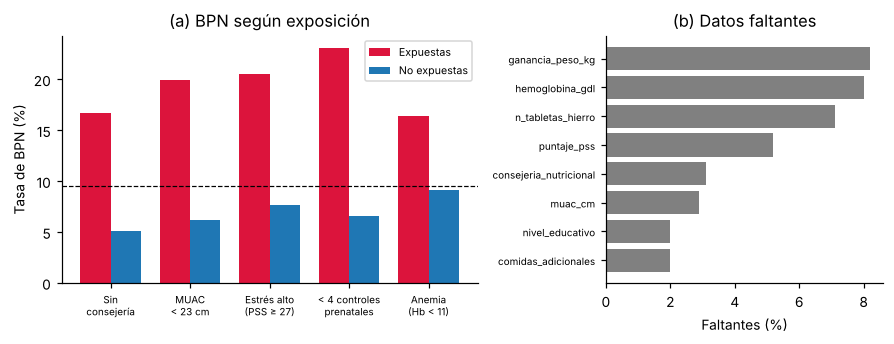

In [23]:
# Figura 1 (descriptiva): tasa de BPN por exposición y faltantes — se construye con el entrenamiento
fl_tr = BanderasClinicas().transform(LimpiarRangos().transform(X_tr))
expo = {
    "Sin consejería nutricional": (X_tr["consejeria_nutricional"] == "no"),
    "MUAC < 23 cm": (fl_tr["muac_lt23"] == 1),
    "Estrés alto (PSS ≥ 27)": (fl_tr["estres_cat"] == "alto"),
    "< 4 controles prenatales": (fl_tr["anc_lt4"] == 1),
    "Anemia (Hb < 11)": (fl_tr["anemia"] == 1),
}
fig, ax = plt.subplots(1, 2, figsize=(8.2, 3.2), gridspec_kw={"width_ratios": [1.5, 1]})
nombres = list(expo)
exp_ = [y_tr[m].mean() * 100 for m in expo.values()]
noexp = [y_tr[~m].mean() * 100 for m in expo.values()]
xx = np.arange(len(nombres)); w = 0.38
ax[0].bar(xx - w / 2, exp_, w, label="Expuestas", color="crimson"); ax[0].bar(xx + w / 2, noexp, w, label="No expuestas", color="C0")
ax[0].axhline(y_tr.mean() * 100, color="k", ls="--", lw=0.8)
ax[0].set_xticks(xx); ax[0].set_xticklabels(["Sin\nconsejería", "MUAC\n< 23 cm", "Estrés alto\n(PSS ≥ 27)", "< 4 controles\nprenatales", "Anemia\n(Hb < 11)"], fontsize=6.5)
ax[0].set_ylabel("Tasa de BPN (%)"); ax[0].legend(fontsize=7); ax[0].set_title("(a) BPN según exposición")
mis = calidad["faltantes_%"].sort_values()
mis = mis[mis > 0]
ax[1].barh(mis.index, mis.values, color="gray"); ax[1].set_xlabel("Faltantes (%)"); ax[1].tick_params(axis="y", labelsize=6.5); ax[1].set_title("(b) Datos faltantes")
fig.tight_layout(); fig.savefig(RES / "fig1_datos.png", dpi=200); plt.show()

In [24]:
# Cifras clave para el informe
clave_json = dict(
    n=int(len(X)), n_bpn=int(y.sum()), prevalencia=float(y.mean()), n_train=int(len(X_tr)), n_test=int(len(X_te)),
    modelo_final=MODELO_FINAL, hiperparametros=gs.best_params_, umbral=float(THR), techo=techo,
    prueba={k: float(v) for k, v in pt.items()}, confusion=dict(TP=int(tp), FN=int(fn), FP=int(fp), TN=int(tn)),
)
(RES / "metricas_clave.json").write_text(json.dumps(clave_json, indent=2, default=str))
print(json.dumps(clave_json, indent=2, default=str))

{
  "n": 6000,
  "n_bpn": 572,
  "prevalencia": 0.09533333333333334,
  "n_train": 4800,
  "n_test": 1200,
  "modelo_final": "Log\u00edstica L2 (Ridge)",
  "hiperparametros": {
    "modelo__C": 0.01
  },
  "umbral": 0.09700505260509194,
  "techo": {
    "pr_auc": 0.30865447046449024,
    "roc_auc": 0.7511752447416885,
    "recall_top20": 0.5350877192982456
  },
  "prueba": {
    "pr_auc": 0.32008559732716324,
    "roc_auc": 0.7464702271332107,
    "recall_top20": 0.5526315789473685,
    "recall": 0.6666666666666666,
    "precision": 0.18446601941747573,
    "f2": 0.4377880184331797,
    "brier": 0.07786948498408082
  },
  "confusion": {
    "TP": 76,
    "FN": 38,
    "FP": 336,
    "TN": 750
  }
}
